# Setup

In [1]:
# Cloning github repo
!git clone https://github.com/JoshuaDSah/CP101_FP.git /content/CP101_FP

fatal: destination path '/content/CP101_FP' already exists and is not an empty directory.


In [2]:
# Installing needed packages
%cd /content/CP101_FP
!pip install -r requirements.txt

/content/CP101_FP


In [3]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import contextily as cx
import os

In [4]:
# Set working directory
os.chdir("/content/CP101_FP")

# Loading in Dataset

In [5]:
ca_transit_routes = gpd.read_file("data/raw/CA_Transit_Routes")

# Data Cleaning

In [6]:
ca_transit_routes.head()

,OBJECTID,shape_id,route_name,n_trips,route_type,route_leng,route_id,pct_route_,shn_route,agency,district_n,Shape_Leng,geometry
0,1,53252,E16 Elk Grove Commuter Route,2.0,3,98459.01,E16,52.3,"50, 51, 99",City of Elk Grove,03 - Marysville / Sacramento,38373.588034,"LINESTRING (-13525702.406 4660880.976, -135255..."
1,2,40,12S RTA - Los Osos / Morro Bay / San Luis Obispo,14.0,3,121800.51,12S,54.0,"1, 101",San Luis Obispo Regional Transit Authority,05 - San Luis Obispo / Santa Barbar,45548.509379,"LINESTRING (-13450387.424 4208812.563, -134504..."
2,3,2044-A-IB,10 Clearlake / Clearlake Park North Loop,47.0,3,76924.27,2044,20.5,"29, 53",Lake Transit Authority,01 - Eureka,30172.839625,"LINESTRING (-13649522.297 4711643.045, -136495..."
3,4,23002,11 11 Petaluma Crosstown,140.0,3,13543.47,6289,1.2,101,City of Petaluma,04 - Bay Area / Oakland,5260.267625,"LINESTRING (-13650192.551 4614545.175, -136502..."
4,5,15,41,5.0,3,78504.52,9,63.7,86,Imperial County Transportation Commission,11 - San Diego,28602.778795,"LINESTRING (-12861187.162 3892362.963, -128611..."


In [7]:
print(len(ca_transit_routes))

4549


In [8]:
# Checking data types
ca_transit_routes.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 4549 entries, 0 to 4548
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    4549 non-null   int32   
 1   shape_id    4549 non-null   object  
 2   route_name  4513 non-null   object  
 3   n_trips     4549 non-null   float64 
 4   route_type  4549 non-null   object  
 5   route_leng  4549 non-null   float64 
 6   route_id    4549 non-null   object  
 7   pct_route_  4549 non-null   float64 
 8   shn_route   4549 non-null   object  
 9   agency      4549 non-null   object  
 10  district_n  4549 non-null   object  
 11  Shape_Leng  4549 non-null   float64 
 12  geometry    4549 non-null   geometry
dtypes: float64(4), geometry(1), int32(1), object(7)
memory usage: 444.4+ KB


In [9]:
# Create a copy for cleaning
transit_routes = ca_transit_routes.copy()

# Standardize column names
transit_routes.columns = transit_routes.columns.str.strip().str.lower()

# Removing whitespace for each column
for column in ca_transit_routes.columns:
  if ca_transit_routes[column].dtype == 'object':
    ca_transit_routes[column] = ca_transit_routes[column].str.strip()

# Changing data types
transit_routes['objectid'] = transit_routes['objectid'].astype(str)

# Display cleaned dataset
transit_routes.head()

,objectid,shape_id,route_name,n_trips,route_type,route_leng,route_id,pct_route_,shn_route,agency,district_n,shape_leng,geometry
0,1,53252,E16 Elk Grove Commuter Route,2.0,3,98459.01,E16,52.3,"50, 51, 99",City of Elk Grove,03 - Marysville / Sacramento,38373.588034,"LINESTRING (-13525702.406 4660880.976, -135255..."
1,2,40,12S RTA - Los Osos / Morro Bay / San Luis Obispo,14.0,3,121800.51,12S,54.0,"1, 101",San Luis Obispo Regional Transit Authority,05 - San Luis Obispo / Santa Barbar,45548.509379,"LINESTRING (-13450387.424 4208812.563, -134504..."
2,3,2044-A-IB,10 Clearlake / Clearlake Park North Loop,47.0,3,76924.27,2044,20.5,"29, 53",Lake Transit Authority,01 - Eureka,30172.839625,"LINESTRING (-13649522.297 4711643.045, -136495..."
3,4,23002,11 11 Petaluma Crosstown,140.0,3,13543.47,6289,1.2,101,City of Petaluma,04 - Bay Area / Oakland,5260.267625,"LINESTRING (-13650192.551 4614545.175, -136502..."
4,5,15,41,5.0,3,78504.52,9,63.7,86,Imperial County Transportation Commission,11 - San Diego,28602.778795,"LINESTRING (-12861187.162 3892362.963, -128611..."


In [10]:
# Print length of cleaned transit routes dataset
print(len(transit_routes))

4549


In [11]:
# Checking number of routes with no geometry
print(transit_routes['geometry'].isna().sum())

0


In [12]:
# Checking CRS
print(transit_routes.crs)

# Converting to EPSG:2227
transit_routes = transit_routes.to_crs("EPSG:2227")

EPSG:3857


In [13]:
# Checking if CRS conversion worked
print(transit_routes.crs)

EPSG:2227


## Loading Bay Area Counties Polygons for Spatial Join/Filter

In [14]:
# Loading polygons for Bay Area Counties
bay_area_counties = gpd.read_file("data/raw/bay_area_counties_polygons")

bay_area_counties.head()

,fipst,fipco,coname,geometry
0,06,097,None,"POLYGON ((-122.93507 38.31396, -122.93511 38.3..."
1,06,075,None,"MULTIPOLYGON (((-123.17384 37.77573, -123.1737..."
2,06,041,None,"POLYGON ((-122.7864 37.88695, -122.78705 37.88..."
3,06,055,None,"POLYGON ((-122.4639 38.70521, -122.4639 38.705..."
4,06,095,None,"POLYGON ((-122.06479 38.31592, -122.06509 38.3..."


In [15]:
# Checking data types and length of bay_area_counties
bay_area_counties.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   fipst     9 non-null      object  
 1   fipco     9 non-null      object  
 2   coname    0 non-null      object  
 3   geometry  9 non-null      geometry
dtypes: geometry(1), object(3)
memory usage: 420.0+ bytes


In [16]:
# Filtering to only routes that are in Santa Clara County or San Francisco County
sf_scc = bay_area_counties[(bay_area_counties['fipco'] == '075') | (bay_area_counties['fipco'] == '085')]

sf_scc = sf_scc.to_crs("EPSG:2227")

sf_scc

,fipst,fipco,coname,geometry
1,06,075,None,"MULTIPOLYGON (((5788982.882 2115962.452, 57890..."
6,06,085,None,"POLYGON ((6111947.826 1899186.651, 6111957.514..."


In [17]:
# Checking data types and length of bay_area_counties
sf_scc.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 2 entries, 1 to 6
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   fipst     2 non-null      object  
 1   fipco     2 non-null      object  
 2   coname    0 non-null      object  
 3   geometry  2 non-null      geometry
dtypes: geometry(1), object(3)
memory usage: 188.0+ bytes


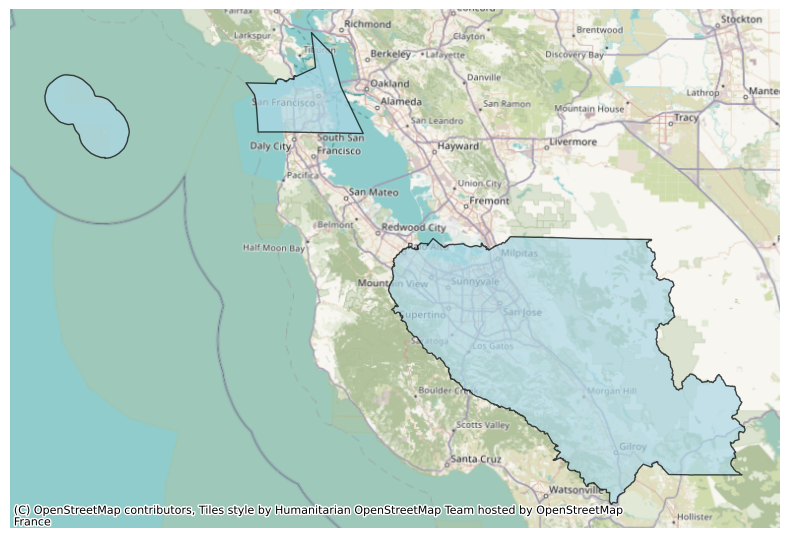

In [18]:
# Plotting SF and SCC polygons as a visual check
fig, ax = plt.subplots(figsize=(8, 8))
sf_scc.plot(edgecolor="black", facecolor="lightblue", alpha=0.7, legend=True, ax=ax)
cx.add_basemap(ax, crs=sf_scc.crs)
ax.set_axis_off()

plt.tight_layout()
plt.show()

## Spatial Join of CA Transit Routes & SF and Santa Clara Counties Boundaries

In [19]:
# Spatial join between CA Transit Routes dataset and SF and SCC boundaries
transit_routes_sf_sc = gpd.sjoin(transit_routes, sf_scc, how = "inner", predicate = "intersects")

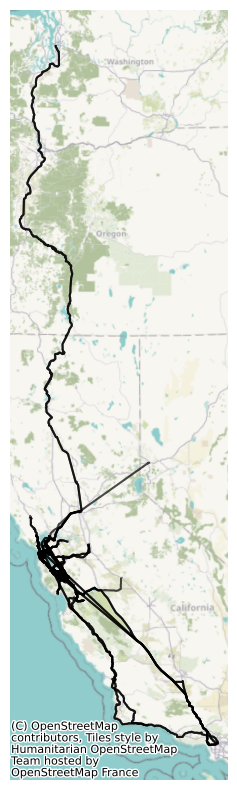

In [20]:
# Plotting map of spatial join as a spatial check
fig, ax = plt.subplots(figsize=(8, 8))
transit_routes_sf_sc.plot(edgecolor="black", legend = True, ax=ax, alpha=0.7)
cx.add_basemap(ax, crs=transit_routes_sf_sc.crs)
ax.set_axis_off()

plt.tight_layout()
plt.show()

In [21]:
# Display transit routes in SF & SC counties
transit_routes_sf_sc.head()

,objectid,shape_id,route_name,n_trips,route_type,route_leng,route_id,pct_route_,shn_route,agency,district_n,shape_leng,geometry,index_right,fipst,fipco,coname
5,6,p_1438488,Express,7.0,2,247256.04,Express,3.4,"84, 85, 92, 101, 237, 280, 380, 880",Peninsula Corridor Joint Powers Board,04 - Bay Area / Oakland,95102.017887,"LINESTRING (6153721.487 1945408.623, 6153707.1...",6,06,085,None
5,6,p_1438488,Express,7.0,2,247256.04,Express,3.4,"84, 85, 92, 101, 237, 280, 380, 880",Peninsula Corridor Joint Powers Board,04 - Bay Area / Oakland,95102.017887,"LINESTRING (6153721.487 1945408.623, 6153707.1...",1,06,075,None
8,9,004A_shp,Orange-S Richmond to Berryessa/North San Jose,343.0,1,267102.50,Orange,0.9,"13, 24, 77, 80, 112, 237, 238, 262, 580, 980",San Francisco Bay Area Rapid Transit District,04 - Bay Area / Oakland,102957.073255,"LINESTRING (6027304.37 2168840.026, 6027417.38...",6,06,085,None
35,36,Route40shapeA,GR Route 40 Merced - San Jose,6.0,3,624189.70,40,94.5,"5, 33, 59, 85, 87, 99, 101, 152, 156, 165, 280",San Joaquin Joint Powers Authority,10 - Stockton,238739.627989,"LINESTRING (6568408.37 1934337.959, 6568481.08...",6,06,085,None
81,82,611-A-IB,Intercounty Gilroy Greyhound,8.0,3,125148.71,611,71.2,"25, 101, 129, 156",San Benito County Local Transportation Authority,05 - San Luis Obispo / Santa Barbar,47735.263871,"LINESTRING (6303024.943 1767997.8, 6303087.818...",6,06,085,None


In [22]:
# Checking columns, data types, and length in joined data frame
transit_routes_sf_sc.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 501 entries, 5 to 4235
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   objectid     501 non-null    object  
 1   shape_id     501 non-null    object  
 2   route_name   501 non-null    object  
 3   n_trips      501 non-null    float64 
 4   route_type   501 non-null    object  
 5   route_leng   501 non-null    float64 
 6   route_id     501 non-null    object  
 7   pct_route_   501 non-null    float64 
 8   shn_route    501 non-null    object  
 9   agency       501 non-null    object  
 10  district_n   501 non-null    object  
 11  shape_leng   501 non-null    float64 
 12  geometry     501 non-null    geometry
 13  index_right  501 non-null    int64   
 14  fipst        501 non-null    object  
 15  fipco        501 non-null    object  
 16  coname       0 non-null      object  
dtypes: float64(4), geometry(1), int64(1), object(11)
memory usage: 86.6+ 

In [23]:
print("Routes Removed in Filtering to SF & Santa Clara County:", len(transit_routes) - len(transit_routes_sf_sc))

Routes Removed in Filtering to SF & Santa Clara County: 4048


In [24]:
# Checking number of routes with no geometry
print(transit_routes_sf_sc['geometry'].isna().sum())

0


# Importing Cleaned Data Frame to Processed Folder

In [27]:
# Importing cleaned data frame
transit_routes_export = transit_routes_sf_sc.copy()

folder_path = 'data/processed'
os.makedirs(folder_path, exist_ok=True)

file_name = 'transit_routes_cleaned.csv'
import_path = os.path.join(folder_path, file_name)

transit_routes_export.to_csv(import_path, index=False)